# Lab 01 - Sentiment Analysis Using Traditional Machine Learning

### 1. Download and load dataset

In [1]:
import pandas as pd

amazon = pd.read_csv(r"C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-01-Machine-Learning\data\sentiment+labelled+sentences\sentiment labelled sentences\amazon_cells_labelled.txt",
                       sep="\t", header=None, names=["text", "sentiment"])

imdb = pd.read_csv(r"C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-01-Machine-Learning\data\sentiment+labelled+sentences\sentiment labelled sentences\imdb_labelled.txt",
                       sep="\t", header=None, names=["text", "sentiment"])

yelp = pd.read_csv(r"C:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-01-Machine-Learning\data\sentiment+labelled+sentences\sentiment labelled sentences\yelp_labelled.txt",
                       sep="\t", header=None, names=["text", "sentiment"])


#identify the source of each dataset
amazon["source"]="Amazon"
imdb["source"]="IMDB"
yelp["source"]="Yelp"

df = pd.concat([amazon, imdb, yelp], ignore_index=True)

df.head()


,text,sentiment,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


In [2]:
print(df.shape)
print(df.columns)



(2748, 3)
Index(['text', 'sentiment', 'source'], dtype='object')


### 2. Perform basic text preprocessing

In [3]:

import re

#rename column 
df = df.rename(columns={"text": "review"})

#Check and remove if there is any incomplete rows, check label values
df = df.dropna(subset=["review", "sentiment"]).copy()
df["sentiment"]=pd.to_numeric(df["sentiment"], errors="coerce")
df=df[df["sentiment"].isin([0,1])].copy()
df["sentiment"]=df["sentiment"].astype(int)


def clean_txt(text):
    #convert to lowercase
    text=str(text).lower()

    #remove punctuations and symbols
    text=re.sub(r"[^a-z0-9\s]", " ", text)

    #remove extra whitespace
    text=re.sub(r"\s+", " ", text)

    return text.strip()

df["clean_txt"]=df["review"].apply(clean_txt)
df=df[df["clean_txt"] != ""].copy()

print("Original and Cleaned text:")
display(df[["review", "clean_txt"]].head(10))

print("Missing values after cleaning:")
print(df[["review", "sentiment", "clean_txt"]].isna().sum())
print("Exact duplicate cleaned reviews:", df["clean_txt"].duplicated().sum())

Original and Cleaned text:


,review,clean_txt
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


Missing values after cleaning:
review       0
sentiment    0
clean_txt    0
dtype: int64
Exact duplicate cleaned reviews: 28


Extra cleaning part - remove duplicates

In [5]:
starting_rows= len(df)
label_counts= df.groupby("clean_txt")["sentiment"].nunique()
conflicting_texts= set(label_counts[label_counts>1].index)

if conflicting_texts:
    df= df[df["clean_txt"].isin(conflicting_texts)].copy()

df= df.drop_duplicates(subset=["clean_txt"]).reset_index(drop=True)

print("Rows befor duplicate checks:", starting_rows)
print("Conflicting cleaned texts excluded:", len(conflicting_texts))
print("Rows after duplicate checks:", len(df))

Rows befor duplicate checks: 2720
Conflicting cleaned texts excluded: 0
Rows after duplicate checks: 2720


### 3. Explore text data

Class distribution (0 = Negative, 1 = Positive):
sentiment
0    1348
1    1372
Name: count, dtype: int64
Distribution across review sources:


Sentiment,0,1
Source,,
Amazon,494,489
IMDB,359,384
Yelp,495,499


Example positive reviews:


,review,clean_txt
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
4,The mic is great.,the mic is great
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
10,And the sound quality is great.,and the sound quality is great


Example negative reviews:


,review,clean_txt
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
8,"Needless to say, I wasted my money.",needless to say i wasted my money


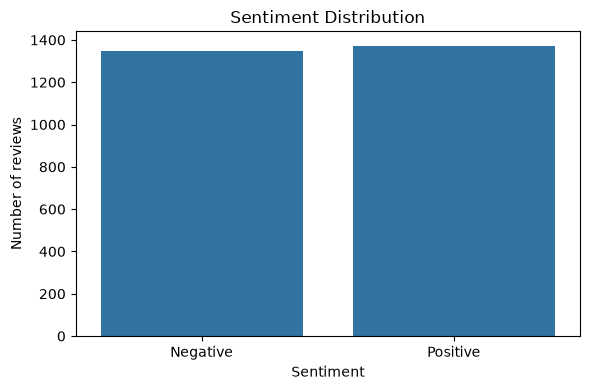

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Class distribution (0 = Negative, 1 = Positive):")
print(df["sentiment"].value_counts().sort_index())

print("Distribution across review sources:")
display(pd.crosstab(df["source"], df["sentiment"], rownames=["Source"], colnames=["Sentiment"]))

print("Example positive reviews:")
display(df.loc[df["sentiment"] == 1, ["review", "clean_txt"]].head(5))

print("Example negative reviews:")
display(df.loc[df["sentiment"] == 0, ["review", "clean_txt"]].head(5))

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="sentiment", order=[0,1], color="tab:blue")
plt.xticks([0,1], ["Negative", "Positive"])
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.title("Sentiment Distribution")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sentiment_distribution.png", dpi=150)
plt.show()

Common words in positive reviews: [('great', 183), ('good', 173), ('film', 91), ('movie', 87), ('phone', 83), ('really', 60), ('food', 60), ('best', 59), ('like', 58), ('place', 57), ('service', 55), ('not', 54)]
Common words in negative reviews: [('not', 248), ('bad', 96), ('movie', 95), ('phone', 79), ('film', 72), ('just', 69), ('like', 66), ('food', 65), ('time', 62), ('don', 58), ('good', 57), ('place', 55)]


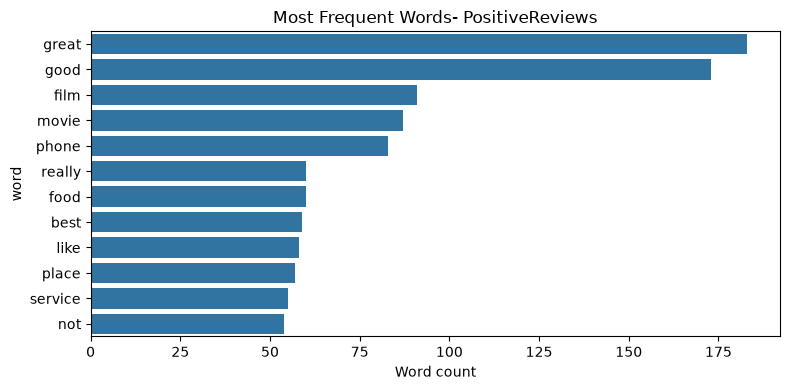

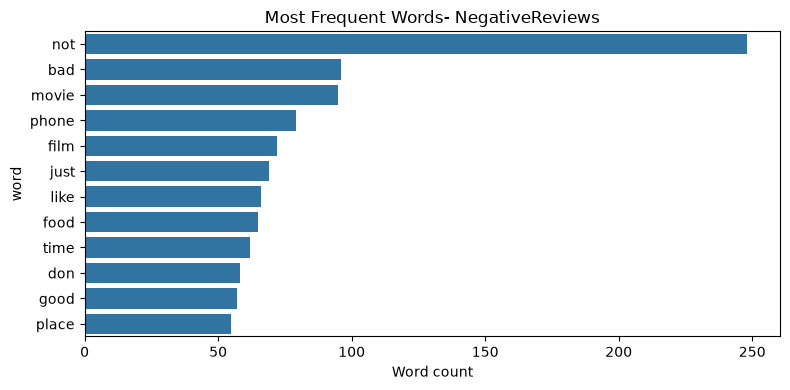

In [8]:
#stop words are ignored only for frequencyb plots
from collections import Counter as FreqDist
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

frequency_stopwords= set(ENGLISH_STOP_WORDS)-{"not", "no", "nor"}

def top_words(label, n=12):
    sentences= df.loc[df["sentiment"]==label, "clean_txt"]
    words= " ".join(sentences).split()
    words= [w for w in words if len(w)>2 and w not in frequency_stopwords]
    return FreqDist(words).most_common(n)

positive_words= top_words(1)
negative_words= top_words(0)
print("Common words in positive reviews:", positive_words)
print("Common words in negative reviews:", negative_words)

for label_name, pairs, filename in [
    ("Positive", positive_words, "top_words_positive.png"),
    ("Negative", negative_words, "top_words_negative.png")

]:
    words= [w for w, count in pairs]
    counts= [count for w, count in pairs]
    plt.figure(figsize=(8,4))
    sns.barplot(x=counts, y=words, color="tab:blue")
    plt.title(f"Most Frequent Words- {label_name}Reviews")
    plt.xlabel("Word count")
    plt.ylabel("word")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR/filename, dpi=150)
    plt.show()

### 4. Split the dataset

In [15]:

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test= train_test_split(
    df["clean_txt"], df["sentiment"],
    test_size=0.20, random_state=42, stratify=df["sentiment"]
)

print("Training examples:", len(x_train))
print("Test examples:", len(x_test))
print("Training sentiment proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

Training examples: 2176
Test examples: 544
Training sentiment proportions:
sentiment
0    0.495
1    0.505
Name: proportion, dtype: float64


### 5. Create Bag-of-Words(BoW) Features

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer= CountVectorizer()
x_train_bow= vectorizer.fit_transform(x_train)
x_test_bow= vectorizer.transform(x_test)

print("Training BoW matrix shape:", x_train_bow.shape)
print("Test BoW matrix shape:", x_test_bow.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Example vocabulary terms:", vectorizer.get_feature_names_out()[:20])

Training BoW matrix shape: (2176, 4454)
Test BoW matrix shape: (544, 4454)
Vocabulary size: 4454
Example vocabulary terms: ['00' '10' '100' '11' '12' '13' '15' '15g' '17' '18' '18th' '1928' '1947'
 '1948' '1949' '1971' '1973' '1979' '1980' '1986']


### 6. Train a machine learning model

Logistic Regression

In [17]:
from sklearn.linear_model import LogisticRegression

model= LogisticRegression(max_iter=1000, random_state=42)
model.fit(x_train_bow, y_train)
print(":Logistic Regretion model trained")

:Logistic Regretion model trained


### 7. Evaluate model performance

Evaluation Metrics:
accuracy  : 0.8051
precision : 0.8000
recall    : 0.8175
f1_score  : 0.8087
Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.79      0.80       270
    Positive       0.80      0.82      0.81       274

    accuracy                           0.81       544
   macro avg       0.81      0.81      0.81       544
weighted avg       0.81      0.81      0.81       544



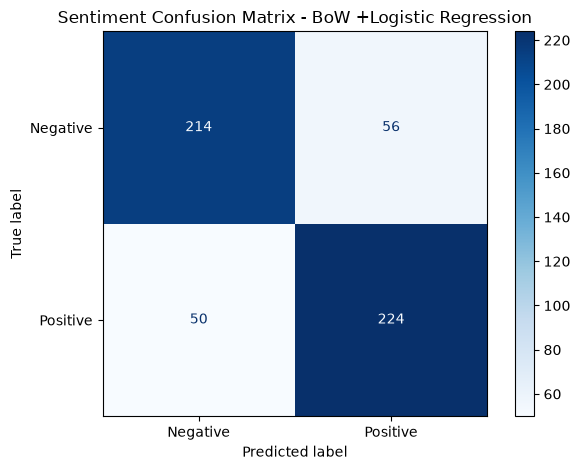

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

y_pred= model.predict(x_test_bow)
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1_score": f1_score(y_test, y_pred, zero_division=0),
}

print("Evaluation Metrics:")
for name, value in metrics.items():
    print(f"{name:10s}: {value:.4f}")
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))

pd.DataFrame([metrics]).to_csv(RESULTS_DIR/"evaluation_metrics.csv", index=False)

import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)
plt.title("Sentiment Confusion Matrix - BoW +Logistic Regression")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()


### 8. Test the model with new sentences

In [20]:
new_sentences = [
    "I absolutely loved this movie!",
    "The food was cold and disappointing.",
    "This product works perfectly.",
    "I would not recommend it to anyone.",
]
new_clean = [clean_txt(sentence) for sentence in new_sentences]
new_vectors = vectorizer.transform(new_clean)
new_labels = model.predict(new_vectors)

predictions = pd.DataFrame({
    "sentence": new_sentences,
    "clean_text": new_clean,
    "predicted_label": new_labels,
    "predicted_sentiment": ["Positive" if value == 1 else "Negative" for value in new_labels],
})
display(predictions)
predictions.to_csv(RESULTS_DIR / "new_sentence_predictions.csv", index=False)

,sentence,clean_text,predicted_label,predicted_sentiment
0,I absolutely loved this movie!,i absolutely loved this movie,1,Positive
1,The food was cold and disappointing.,the food was cold and disappointing,0,Negative
2,This product works perfectly.,this product works perfectly,1,Positive
3,I would not recommend it to anyone.,i would not recommend it to anyone,0,Negative
